In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_train.csv")
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [2]:
print(df.shape)


(60000, 785)


# Labels and its meaning



| Label | Description |
| :--- | :--- |
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |



# Viewing the dataset

Labels: [2, 9, 6, 0, 3, 4, 4, 5, 4, 8]


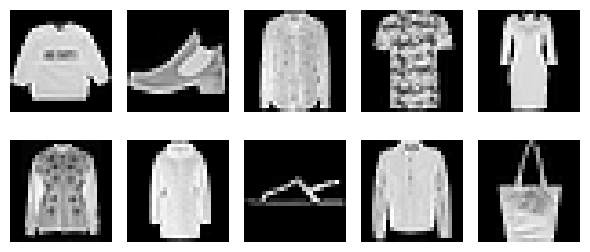

In [3]:
import matplotlib.pyplot as plt

labels = df["label"].head(10).to_list()
print(f"Labels: {labels}")

fig, axes = plt.subplots(2, 5, figsize=(6, 3))
axes = axes.flatten()

for i in range(10):
    img_raw = df.drop(columns=['label']).iloc[i].values
    img_shaped = img_raw.reshape(28,28)
    axes[i].imshow(img_shaped, cmap='gray')
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# Check if test has labels

If it didnt, I'll have to use train and split a test there
However its not needed because theres labels in test.csv

In [4]:
df2 = pd.read_csv("/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_test.csv")
df2.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


# Splitting the labels and creating the train test variables

In [9]:
train = df.copy() # Originally 60,000, 785
train_labels = train.pop("label") # removes the label column from the set
train = train.T # now 784, 60,000 where every column is an image

test = df2.copy() # Originally 10,000, 785
test_labels = test.pop("label") # removes the label column from the set
test = test.T # now 784, 10,000

In [10]:
print("TEST: ", test.shape)
print("TRAIN: ", train.shape)

TEST:  (784, 10000)
TRAIN:  (784, 60000)


# Normalizing the input, train and test
##### Very important step, I separated it so you can see it

In [11]:
test = test.astype(np.float64) / 255.0
train = test.astype(np.float64) / 255.0

# Initializing the weights and biases
##### Plus some overcomplicated kaiming init stuff

In [12]:
generate = np.random.default_rng(seed=67) # this is the generator of reproducible random numbers, funny number yes yes

def kaiming_init(Weights,activation_type, alpha= 0.01):
    activation_type = activation_type.lower().strip()
    n_in = Weights.shape[1]
    if activation_type == "relu":
        return Weights * np.sqrt(2/n_in)
    elif activation_type == "leaky_relu":
        return Weights * np.sqrt(2/((1+alpha**2) * n_in))
    else:
        raise ValueError("2nd parameter either: relu or leaky_relu")

# INPUT LAYER WEIGHTS AND BIAS
W1 = generate.standard_normal(size = (25, 784)) # 25 "neurons" by 784 columns
b1 = np.zeros((25, 1)) 

# LAYER 1
W2 = generate.standard_normal(size = (20,25)) # 20 "neurons" by 25 features from input neurons
b2 = np.zeros((20,1))

# LAYER 2
W3 = generate.standard_normal(size = (15, 20)) # 15 "neurons" by 20 features from previous layer
b3 = np.zeros((15,1))

# OUTPUT LAYER
W4 = generate.standard_normal(size = (10, 15)) # 10 output "neurons" from previous layer
b4 = np.zeros((10,1))

activation_type = "relu"
W1, W2, W3, W4 = [
                    kaiming_init(W, activation_type) 
                    for W in (W1, W2, W3, W4)
                 ]

# Yes yes, ik. I overcomplicated this part

# Helper Functions

In [13]:
def weightedSum(W, b, x):
    return W @ x + b

def relu(Z):
    return np.maximum(0, Z)

def softMax(Z):
    Z = np.asarray(Z) #safety net incase what was passed is a dataframe, not really neccesary if u know what ur doing, i just like keeping that there
    exp_Z = np.exp(Z - np.max(Z, axis=0, keepdims = True))
    return exp_Z / np.sum(exp_Z, axis=0, keepdims = True)


# Training Variables

In [ ]:
epochs = 100


# Training Algorithm